# Incremental PCA on the Iris dataset: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/decomposition/plot_incremental_pca.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/decomposition/plot_incremental_pca.html)).

**Scenario:** the bundled Iris data (150 x 4) projected to two components by
`IncrementalPCA(n_components=2, batch_size=10)` and by `PCA(n_components=2)`; the example reports the mean
absolute unsigned difference of the two projections.

**Adaptations:**
- Plots are drawn side by side at a small size instead of two 8x8 figures.
- Extra checks on the same data (not in the gallery script): every learned IncrementalPCA attribute
  (`components_`, `explained_variance_`, `explained_variance_ratio_`, `singular_values_`, `mean_`, `var_`,
  `noise_variance_`, `n_samples_seen_`, `batch_size_`), an explicit `partial_fit` loop over the same 15 batches,
  the default `batch_size` (`5 * n_features`), `whiten=True` with `inverse_transform`, `get_covariance`, and a
  Float32 fit (values compared; the Float64 promotion sklearn applies to multi-batch Float32 fits is a documented
  Moxie difference).
- Labels stay on the Python side; they only colour the plot.

**Determinism:** deterministic (batched exact SVDs), so every quantity is compared numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("decomposition/plot_incremental_pca")

## 1. scikit-learn (Python reference)

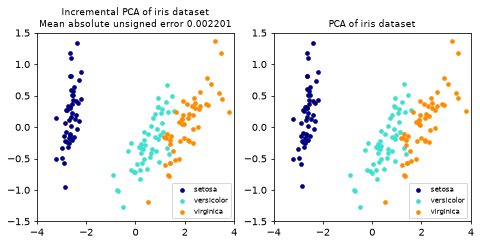

err: 0.0022012210262586152 | default batch_size_: 20 | Float32 output float64


In [2]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA, IncrementalPCA

iris = load_iris()
X = iris.data
y = iris.target

n_components = 2
ipca = IncrementalPCA(n_components=n_components, batch_size=10)
X_ipca = ipca.fit_transform(X)

pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X)

colors = ["navy", "turquoise", "darkorange"]
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), dpi=70)
for ax, (X_transformed, title) in zip(axes, [(X_ipca, "Incremental PCA"), (X_pca, "PCA")]):
    for color, i, target_name in zip(colors, [0, 1, 2], iris.target_names):
        ax.scatter(X_transformed[y == i, 0], X_transformed[y == i, 1], color=color, lw=2, label=target_name, s=8)
    if "Incremental" in title:
        err = np.abs(np.abs(X_pca) - np.abs(X_ipca)).mean()
        ax.set_title(title + " of iris dataset\nMean absolute unsigned error %.6f" % err, fontsize=9)
    else:
        ax.set_title(title + " of iris dataset", fontsize=9)
    ax.legend(loc="best", shadow=False, scatterpoints=1, fontsize=7)
    ax.axis([-4, 4, -1.5, 1.5])
plt.show()

# Extra checks on the same data (not part of the gallery script).
sk = {"err": err}
online = IncrementalPCA(n_components=2)
for start in range(0, 150, 10):
    online.partial_fit(X[start:start + 10])
sk["online_components"] = online.components_
sk["online_scores"] = online.transform(X)
default = IncrementalPCA(n_components=2).fit(X)
sk["default_batch"] = default.batch_size_
sk["default_scores"] = default.transform(X)
white = IncrementalPCA(n_components=2, whiten=True, batch_size=25).fit(X)
sk["white_scores"] = white.transform(X)
sk["white_inverse"] = white.inverse_transform(white.transform(X))
sk["covariance"] = ipca.get_covariance()
X32 = X.astype(np.float32)
p32 = IncrementalPCA(n_components=2, batch_size=10).fit(X32)
sk["f32_scores"] = p32.transform(X32)
print("err:", err, "| default batch_size_:", sk["default_batch"], "| Float32 output", sk["f32_scores"].dtype)
nb.share(X=X, X32=X32)

## 2. Moxie (native Mojo)

The same scenario through `moxie.decomposition.IncrementalPCA` and `PCA`; Python only supplies the data files.

In [3]:
%%mojo ipca_iris
from moxie.decomposition import IncrementalPCA, PCA
from numojo import NDArray, Shape, zeros
from moxie_nb_io import load, save, save_floats, save_ints


def rows(X: NDArray[DType.float64], start: Int, stop: Int) raises -> NDArray[DType.float64]:
    """X[start:stop] as an owned contiguous batch."""
    var p = X.shape[1]
    var out = zeros[DType.float64](Shape(stop - start, p))
    for i in range(start, stop):
        for j in range(p):
            out.unsafe_set((i - start) * p + j, X.unsafe_get(i * p + j))
    return out^


def main() raises:
    var X = load("X")
    var ipca = IncrementalPCA(n_components=2, batch_size=10)
    var X_ipca = ipca.fit_transform(X)
    var pca = PCA(n_components=2)
    var X_pca = pca.fit_transform(X)
    save("X_ipca", X_ipca)
    save("X_pca", X_pca)
    save("components", ipca.components_.value())
    save("explained_variance", ipca.explained_variance_.value())
    save("explained_variance_ratio", ipca.explained_variance_ratio_.value())
    save("singular_values", ipca.singular_values_.value())
    save("mean", ipca.mean_.value())
    save("var", ipca.var_.value())
    save_floats("noise_variance", [ipca.noise_variance_])
    save_ints("counts", [ipca.n_samples_seen_, ipca.batch_size_, ipca.n_components_])
    save("covariance", ipca.get_covariance())

    var online = IncrementalPCA(n_components=2)
    for start in range(0, 150, 10):
        _ = online.partial_fit(rows(X, start, start + 10))
    save("online_components", online.components_.value())
    save("online_scores", online.transform(X))

    var default = IncrementalPCA(n_components=2)
    _ = default.fit(X)
    save_ints("default_batch", [default.batch_size_])
    save("default_scores", default.transform(X))

    var white = IncrementalPCA(n_components=2, whiten=True, batch_size=25)
    _ = white.fit(X)
    var z = white.transform(X)
    save("white_scores", z)
    save("white_inverse", white.inverse_transform(z))

    var X32 = load[DType.float32]("X32")
    var p32 = IncrementalPCA[DType.float32](n_components=2, batch_size=10)
    _ = p32.fit(X32)
    save("f32_scores", p32.transform(X32))
    print("n_samples_seen_:", ipca.n_samples_seen_, "| default batch_size_:", default.batch_size_)

n_samples_seen_: 150 | default batch_size_: 20


## 3. Side by side and parity

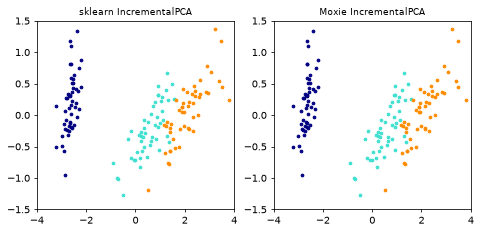

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
IncrementalPCA.fit_transform (X_ipca),PASS,"(150, 2)","(150, 2)",3.55e-15,6.01e-13,"rtol=1e-09, atol=1e-11",,Float64 batched SVD updates (Moxie Jacobi SVD vs LAPACK gesdd) on 15 well-conditioned 10x4 batches; rounding only; same svd_flip rule
PCA.fit_transform (X_pca),PASS,"(150, 2)","(150, 2)",1.42e-14,1.17e-12,"rtol=1e-09, atol=1e-11",,Float64 batched SVD updates (Moxie Jacobi SVD vs LAPACK gesdd) on 15 well-conditioned 10x4 batches; rounding only
mean absolute unsigned error (example output),PASS,(),(),7.12e-16,3.24e-13,"rtol=1e-06, atol=0",,a difference of two projections that agree to 1e-11 each; the 2e-3 error itself is ~1e-11 absolute
components_,PASS,"(2, 4)","(2, 4)",1.14e-15,9.13e-15,"rtol=1e-09, atol=1e-11",,Float64 batched SVD updates (Moxie Jacobi SVD vs LAPACK gesdd) on 15 well-conditioned 10x4 batches; rounding only
explained_variance_,PASS,"(2,)","(2,)",6.22e-15,1.47e-15,"rtol=1e-11, atol=0",,Float64 batched SVD updates (Moxie Jacobi SVD vs LAPACK gesdd) on 15 well-conditioned 10x4 batches; rounding only
explained_variance_ratio_,PASS,"(2,)","(2,)",1.44e-15,1.56e-15,"rtol=1e-11, atol=0",,Float64 batched SVD updates (Moxie Jacobi SVD vs LAPACK gesdd) on 15 well-conditioned 10x4 batches; rounding only
singular_values_,PASS,"(2,)","(2,)",1.78e-14,7.08e-16,"rtol=1e-11, atol=0",,Float64 batched SVD updates (Moxie Jacobi SVD vs LAPACK gesdd) on 15 well-conditioned 10x4 batches; rounding only
mean_,PASS,"(4,)","(4,)",2.22e-16,1.85e-16,"rtol=1e-13, atol=0",,incremental column means; summation order only
var_,PASS,"(4,)","(4,)",8.88e-16,2.87e-16,"rtol=1e-12, atol=0",,incremental (Chan) variance updates; summation order only
noise_variance_,PASS,(),(),1.47e-17,2.07e-15,"rtol=1e-09, atol=0",,Float64 batched SVD updates (Moxie Jacobi SVD vs LAPACK gesdd) on 15 well-conditioned 10x4 batches; rounding only


In [4]:
mx = nb.results["ipca_iris"]
mx_err = np.abs(np.abs(mx["X_pca"]) - np.abs(mx["X_ipca"])).mean()
moxie_nb.side_by_side(sklearn=X_ipca[:5], moxie=mx["X_ipca"][:5])
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), dpi=70)
for ax, (data, title) in zip(axes, [(X_ipca, "sklearn IncrementalPCA"), (mx["X_ipca"], "Moxie IncrementalPCA")]):
    for color, i in zip(colors, [0, 1, 2]):
        ax.scatter(data[y == i, 0], data[y == i, 1], color=color, s=8)
    ax.set_title(title, fontsize=9); ax.axis([-4, 4, -1.5, 1.5])
plt.show()

F64 = "Float64 batched SVD updates (Moxie Jacobi SVD vs LAPACK gesdd) on 15 well-conditioned 10x4 batches; rounding only"
nb.compare("IncrementalPCA.fit_transform (X_ipca)", X_ipca, mx["X_ipca"], rtol=1e-9, atol=1e-11, reason=F64 + "; same svd_flip rule")
nb.compare("PCA.fit_transform (X_pca)", X_pca, mx["X_pca"], rtol=1e-9, atol=1e-11, reason=F64)
nb.compare("mean absolute unsigned error (example output)", err, mx_err, rtol=1e-6,
           reason="a difference of two projections that agree to 1e-11 each; the 2e-3 error itself is ~1e-11 absolute")
nb.compare("components_", ipca.components_, mx["components"], rtol=1e-9, atol=1e-11, reason=F64)
nb.compare("explained_variance_", ipca.explained_variance_, mx["explained_variance"], rtol=1e-11, reason=F64)
nb.compare("explained_variance_ratio_", ipca.explained_variance_ratio_, mx["explained_variance_ratio"], rtol=1e-11, reason=F64)
nb.compare("singular_values_", ipca.singular_values_, mx["singular_values"], rtol=1e-11, reason=F64)
nb.compare("mean_", ipca.mean_, mx["mean"], rtol=1e-13, reason="incremental column means; summation order only")
nb.compare("var_", ipca.var_, mx["var"], rtol=1e-12, reason="incremental (Chan) variance updates; summation order only")
nb.compare("noise_variance_", ipca.noise_variance_, mx["noise_variance"][0], rtol=1e-9, reason=F64)
nb.compare("n_samples_seen_, batch_size_, n_components_", np.array([ipca.n_samples_seen_, ipca.batch_size_, ipca.n_components_]),
           mx["counts"], exact=True)
nb.compare("get_covariance()", sk["covariance"], mx["covariance"], rtol=1e-9, atol=1e-12, reason=F64)
nb.compare("partial_fit loop components_", sk["online_components"], mx["online_components"], rtol=1e-9, atol=1e-11, reason=F64)
nb.compare("partial_fit loop transform", sk["online_scores"], mx["online_scores"], rtol=1e-9, atol=1e-11, reason=F64)
nb.compare("default batch_size_ (5 * n_features)", sk["default_batch"], mx["default_batch"][0], exact=True)
nb.compare("default batch_size transform", sk["default_scores"], mx["default_scores"], rtol=1e-9, atol=1e-11, reason=F64)
nb.compare("whiten=True transform", sk["white_scores"], mx["white_scores"], rtol=1e-9, atol=1e-11, reason=F64)
nb.compare("whiten=True inverse_transform", sk["white_inverse"], mx["white_inverse"], rtol=1e-9, atol=1e-11, reason=F64)
nb.compare("Float32 transform", sk["f32_scores"], mx["f32_scores"], rtol=1e-4, atol=1e-4,
           reason="Float32 batches in both with different reduction orders; sklearn's own Float32 result deviates "
                  "from its Float64 result by ~1e-5 here, so two correct Float32 runs can differ by ~1e-4")
nb.note("Float32 output dtype", "ADAPTED",
        f"sklearn promotes multi-batch Float32 fits to Float64 (transform output {sk['f32_scores'].dtype}); Moxie keeps "
        f"{mx['f32_scores'].dtype} for spectral and transformed arrays (documented in families/decomposition/docs/incremental_pca.md)")
nb.note("plt.figure(figsize=(8, 8)) per method", "ADAPTED", "the two scatter plots are drawn side by side at dpi 70")
nb.report()
nb.assert_parity()